先训练再预测

## KNN（K-近邻算法）

> **核心思想**：物以类聚，人以群分。  
> 如果一个样本在特征空间中的 K 个最相似（即特征空间中距离最近）的样本中的大多数属于某一个类别，则该样本也属于这个类别。

**分类与回归的统一框架：**
- **分类任务**：投票机制（多数表决）
- **回归任务**：均值机制（取平均值）

---

### K 值的影响（超参数选择）

| K 值 | 影响 | 后果 |
| :--- | :--- | :--- |
| **K 值过小** | 模型复杂，容易受异常点干扰 | **过拟合**（对噪声敏感） |
| **K 值过大** | 模型简单，受整体样本分布影响 | **欠拟合**（忽略局部特征） |

分类是投票 回归是均值
相同点：有监督学习（有特征，有标签）
不同点：分类（标签不连续）、回归（标签连续）

### 1. 分类任务（标签离散）

1. 计算未知样本到**每一个**训练样本的距离
2. 将训练样本按距离大小**升序排列**
3. 取出距离最近的 **K 个**训练样本
4. **多数表决（投票）**：统计 K 个样本中哪个类别出现的次数最多
5. 将未知样本归属到**出现次数最多的类别**

---

### 2. 回归任务（标签连续）

1. 计算未知样本到**每一个**训练样本的距离
2. 将训练样本按距离大小**升序排列**
3. 取出距离最近的 **K 个**训练样本
4. **计算平均值**：将这 K 个样本的目标值取均值
5. 将该均值作为未知样本的预测值


---



训练集样本数: 420，测试集样本数: 180
训练集中通过率: 48.10%

KNN (k=5) 测试集准确率: 0.978

分类报告：
              precision    recall  f1-score   support

         未通过       0.95      1.00      0.98        82
          通过       1.00      0.96      0.98        98

    accuracy                           0.98       180
   macro avg       0.98      0.98      0.98       180
weighted avg       0.98      0.98      0.98       180


新学生 (学习8h, 睡眠6.5h) 预测结果: 通过
预测概率: 未通过 20.00%, 通过 80.00%


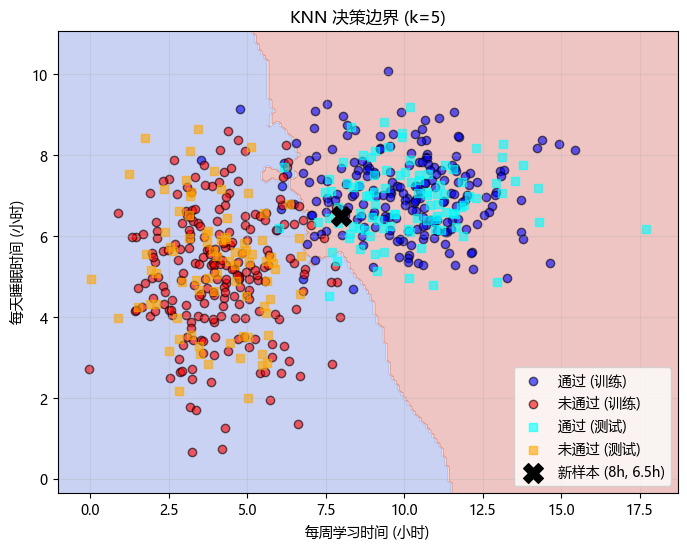

In [2]:
# knn分类案例

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 设置中文字体
plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 固定随机种子
np.random.seed(42)

df = pd.read_csv('study_sleep.csv')
X = df[['StudyHours', 'SleepHours']].values
y = df['Pass'].values

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"\n训练集样本数: {len(X_train)}，测试集样本数: {len(X_test)}")
print(f"训练集中通过率: {np.mean(y_train):.2%}")


k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"\nKNN (k={k}) 测试集准确率: {accuracy:.3f}")

# 打印分类报告
print("\n分类报告：")
print(classification_report(y_test, y_pred, target_names=['未通过', '通过']))

# 假设一个学生每周学习 8 小时，每天睡 6.5 小时
new_student = np.array([[8, 6.5]])
pred_label = knn.predict(new_student)
pred_proba = knn.predict_proba(new_student)  # 返回每个类别的概率（基于邻居投票比例）

print(f"\n新学生 (学习8h, 睡眠6.5h) 预测结果: {'通过' if pred_label[0] == 1 else '未通过'}")
print(f"预测概率: 未通过 {pred_proba[0][0]:.2%}, 通过 {pred_proba[0][1]:.2%}")

# 生成网格点
x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
# 绘制决策区域
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
# 绘制训练集
plt.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], 
            c='blue', label='通过 (训练)', alpha=0.6, edgecolors='k')
plt.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], 
            c='red', label='未通过 (训练)', alpha=0.6, edgecolors='k')
# 绘制测试集
plt.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1], 
            c='cyan', marker='s', label='通过 (测试)', alpha=0.6)
plt.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1], 
            c='orange', marker='s', label='未通过 (测试)', alpha=0.6)
# 标出新样本
plt.scatter(8, 6.5, c='black', marker='X', s=200, label='新样本 (8h, 6.5h)')
plt.xlabel('每周学习时间 (小时)')
plt.ylabel('每天睡眠时间 (小时)')
plt.title(f'KNN 决策边界 (k={k})')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


训练集样本数: 210，测试集样本数: 90
训练集房价均值: 65.04 万

KNN 回归 (k=5) 测试集评估：
MSE  = 41.99
RMSE = 6.48 万元
R²   = 0.940

新房屋 (面积85㎡, 房龄10年) 预测价格: 85.11 万元


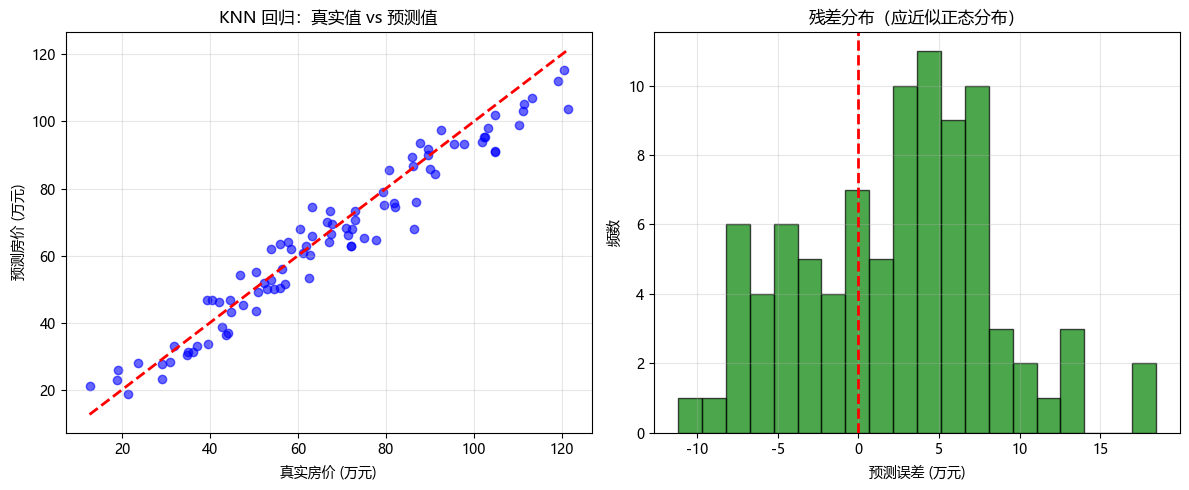

In [6]:
# knn 回归案例

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 设置中文字体
plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 固定随机种子
np.random.seed(42)

df = pd.read_csv('house_price.csv')
X = df[['Area', 'Age']].values
y = df['Price'].values

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"\n训练集样本数: {len(X_train)}，测试集样本数: {len(X_test)}")
print(f"训练集房价均值: {np.mean(y_train):.2f} 万")

k = 5
knn_reg = KNeighborsRegressor(n_neighbors=k)
knn_reg.fit(X_train, y_train)

y_pred = knn_reg.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nKNN 回归 (k={k}) 测试集评估：")
print(f"MSE  = {mse:.2f}")
print(f"RMSE = {rmse:.2f} 万元")
print(f"R²   = {r2:.3f}")

# 假设一个新房屋：面积 85 平米，房龄 10 年
new_house = np.array([[85, 10]])
pred_price = knn_reg.predict(new_house)
print(f"\n新房屋 (面积85㎡, 房龄10年) 预测价格: {pred_price[0]:.2f} 万元")

plt.figure(figsize=(12, 5))

# 子图1：真实值 vs 预测值
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel('真实房价 (万元)')
plt.ylabel('预测房价 (万元)')
plt.title('KNN 回归：真实值 vs 预测值')
plt.grid(alpha=0.3)

# 子图2：残差分布（预测误差）
plt.subplot(1, 2, 2)
residuals = y_test - y_pred
plt.hist(residuals, bins=20, edgecolor='black', alpha=0.7, color='green')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('预测误差 (万元)')
plt.ylabel('频数')
plt.title('残差分布（应近似正态分布）')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## 常用的距离度量方式

### 1. 欧氏距离（Euclidean Distance） 

**直觉**：两点之间的直线距离（最常见的距离），对应维度差值平方和，开平方根。

**公式（二维）：**
$$
d = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2}
$$

**公式（n 维）：**
$$
d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}
$$

### 2. 曼哈顿距离（Manhattan Distance）

**直觉**：只能沿坐标轴方向移动的距离，如同在曼哈顿街区从 A 点走到 B 点。
         也称"城市街区距离"，对应维度差值的绝对值，求和。

**公式：**
$$
d(\mathbf{x}, \mathbf{y}) = \sum_{i=1}^{n} |x_i - y_i|
$$

### 3. 切比雪夫距离（Chebyshev Distance）

**直觉**：可以斜着走，国际象棋中**国王走一步**覆盖的范围（可以斜着走），对应维度差值的绝对值，求最大值。

**公式：**
$$
d(\mathbf{x}, \mathbf{y}) = \max_{i} |x_i - y_i|
$$
###  特征值预处理

> **为什么需要预处理？**  
> 特征的单位或大小范围相差较大时（如 "年龄" 0\~100 和 "年收入" 0\~100000），数值大的特征会对距离计算产生主导影响，导致模型偏向于该特征。

### 1. 归一化（Min-Max Scaling）

**原理**：将原始数据线性变换到 `[min, max]` 区间，默认映射到 `[0, 1]`。

**公式：**
$$
X' = \frac{x - \min(x)}{\max(x) - \min(x)}$$
$$
X'' = X' \times (\text{new\_max} - \text{new\_min}) + \text{new\_min}
$$

**特点**：
- 容易受到最大值和最小值的影响（**鲁棒性较差**）
- 适用于**精确小数据场景**
- 
### 2. 标准化（Standardization / Z-Score Normalization）

**原理**：将原始数据转换为均值为 0，标准差为 1 的标准正态分布。

**公式：**
$$
X' = \frac{x - \text{mean}}{\sigma}
$$

> - `mean`：该特征的均值  
> - `σ`（sigma）：该特征的标准差

**特点**：
- 少量异常点对于平均值影响不大
- 适用于**现代嘈杂大数据场景**

### 交叉验证（Cross-Validation）

> **目的**：将数据集划分为训练集和验证集，多次评估模型，得到更准确可信的模型评分，从而选出最优超参数 K。

### 交叉验证原理（以 n 折交叉验证为例）

1. **第 1 次**：将第 1 份数据作为验证集，其余 `n-1` 份作为训练集
2. **第 2 次**：将第 2 份数据作为验证集，其余 `n-1` 份作为训练集
3. ……以此类推，共训练 `n` 次，评估 `n` 次
4. 计算 `n` 次评估结果的**平均值**，作为该超参数 K 的交叉验证得分
5. 选出**得分最高的 K 值**（如 `K = i` 时得分最好）
6. 使用**全部训练集**（原训练集 + 验证集）对 `K = i` 的模型**重新训练**
7. 最后使用**独立的测试集**对最终模型进行评估


### 网格搜索（Grid Search）

> **自动化调参工具**：网格搜索是一种**超参数优化**方法，它会遍历你指定的所有候选超参数组合，并对每一组组合执行一次**交叉验证评估**，最终自动选出平均分最高的那一组参数。

### 网格搜索的核心逻辑

- **外层循环**：遍历所有超参数组合（如 `n_neighbors` = [3,5,7]，`weights` = ['uniform','distance']，共 3×2 = 6 种组合）
- **内层循环**：对每一组参数，执行一次完整的交叉验证（如 `cv=5`），得到该组参数的平均得分
- **输出结果**：返回交叉验证得分最高的参数组合（`best_params_`）及其得分（`best_score_`）

### 与交叉验证的关系（一句话概括）

> **交叉验证是网格搜索内部的“评分引擎”；网格搜索是交叉验证的“调度者”。**

- **交叉验证**：告诉你“这组参数在数据上表现如何”（打一个分数）。
- **网格搜索**：不断尝试新的参数组合，反复调用交叉验证，最后挑出最佳组合。

### 为什么需要网格搜索？

- **自动化**：避免手动修改代码、重跑、记录分数的繁琐流程。
- **系统化**：确保所有候选参数都被公平评估，不会遗漏。
- **效率**：一次定义好参数网格，程序自动完成所有训练和评估。


原始数据集
    │
    ├── 训练集（用于调参）
    │       │
    │       └── 网格搜索（外层遍历参数组合）
    │               │
    │               ├── 组合1 (K=3, weights='uniform')
    │               │       └── 交叉验证 (cv=5) → 得分1
    │               ├── 组合2 (K=3, weights='distance')
    │               │       └── 交叉验证 (cv=5) → 得分2
    │               ├── 组合3 ...（循环所有组合）
    │               │
    │               └── 选出平均分最高的参数组合（best_params_）
    │
    ├── 使用全部训练集重新训练模型（最佳参数）
    │
    └── 测试集 → 评估最终模型的泛化能力